# Passband Goal Selection (EXT-driven, Fake as Reference)

This notebook selects a recommended passband goal using `ext/` cases (feasibility-first), and shows fake-dataset mean curves for reference.


In [1]:
from __future__ import annotations

from pathlib import Path
import json
import pickle
import re
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root(start: Path) -> Path:
    cur = start.resolve()
    for cand in [cur, *cur.parents]:
        if (cand / 'data').exists() and (cand / 'notebooks').exists():
            return cand
    raise RuntimeError(f'Cannot locate repo root from {start}')

REPO_ROOT = find_repo_root(Path.cwd())
FAKE_DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'
if not FAKE_DATASET_PATH.exists():
    FAKE_DATASET_PATH = REPO_ROOT / 'data' / 'bclf_dataset.pkl'
EXT_DIR = REPO_ROOT / 'data' / 'bandpass_coupled_line_filter_export' / 'ext'
EXT_INDEX_PATH = EXT_DIR / 'index.json'

# --- Goal tuning parameters (editable) ---
S21_PASS_DB = -5.0
S11_PASS_DB = -5.0
TARGET_CENTER_GHZ = 5.2
SEARCH_MIN_GHZ = 4.5
SEARCH_MAX_GHZ = 6.5
MIN_POINTS = 5
MIN_PASS_PROB = 0.02
SMOOTH_PROB_WINDOW = 1  # set >1 to smooth pass probability

print('repo root:', REPO_ROOT)
print('fake dataset:', FAKE_DATASET_PATH, 'exists=', FAKE_DATASET_PATH.exists())
print('ext index:', EXT_INDEX_PATH, 'exists=', EXT_INDEX_PATH.exists())


repo root: /home/zhanghf/projects/vector
fake dataset: /home/zhanghf/projects/vector/data/filter_bnn_online_uaw_uaw_dataset.pkl exists= True
ext index: /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/index.json exists= True


In [2]:
def parse_touchstone_2port(path: Path) -> tuple[np.ndarray, np.ndarray]:
    fmt = None  # RI / MA / DB
    freq_unit = 'HZ'
    rows = []
    with path.open('r', encoding='utf-8', errors='ignore') as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith('!'):
                continue
            if line.startswith('#'):
                parts = line[1:].strip().upper().split()
                for token in ('RI', 'MA', 'DB'):
                    if token in parts:
                        fmt = token
                        break
                for token in ('HZ', 'KHZ', 'MHZ', 'GHZ'):
                    if token in parts:
                        freq_unit = token
                        break
                continue
            vals = line.split()
            try:
                nums = [float(v) for v in vals]
            except ValueError:
                continue
            rows.append(nums)

    if fmt is None:
        raise ValueError(f'No valid touchstone format header in {path}')
    if not rows:
        raise ValueError(f'No numeric data rows in {path}')

    arr = np.asarray(rows, dtype=float)
    if arr.shape[1] < 9:
        raise ValueError(f'Unexpected touchstone column count {arr.shape[1]} in {path}')

    freq_raw = arr[:, 0].astype(float)
    unit_scale = {'HZ': 1.0, 'KHZ': 1e3, 'MHZ': 1e6, 'GHZ': 1e9}
    freq_hz = freq_raw * unit_scale.get(freq_unit, 1.0)

    def _pair_to_complex(a: np.ndarray, b: np.ndarray) -> np.ndarray:
        if fmt == 'RI':
            return a + 1j * b
        if fmt == 'MA':
            return a * np.exp(1j * np.deg2rad(b))
        mag = 10.0 ** (a / 20.0)
        return mag * np.exp(1j * np.deg2rad(b))

    # 2-port touchstone ordering: S11, S21, S12, S22
    s11 = _pair_to_complex(arr[:, 1], arr[:, 2])
    s21 = _pair_to_complex(arr[:, 3], arr[:, 4])
    s12 = _pair_to_complex(arr[:, 5], arr[:, 6])
    s22 = _pair_to_complex(arr[:, 7], arr[:, 8])

    s_params = np.zeros((2, 2, len(freq_hz)), dtype=complex)
    s_params[0, 0, :] = s11
    s_params[1, 0, :] = s21
    s_params[0, 1, :] = s12
    s_params[1, 1, :] = s22
    return freq_hz, s_params

def to_db(x: np.ndarray) -> np.ndarray:
    return 20.0 * np.log10(np.maximum(np.abs(x), 1e-15))


In [3]:
# Load EXT cases
with EXT_INDEX_PATH.open('r', encoding='utf-8') as f:
    ext_index = json.load(f)
ext_records = ext_index.get('records', {}) if isinstance(ext_index, dict) else {}

ext_total_records = len(ext_records)
ext_missing = 0
ext_skipped = 0
ext_valid = 0
freq_ref_hz = None
ext_s21_db = []
ext_s11_db = []
ext_valid_records = []

for rec in ext_records.values():
    filename = rec.get('filename') if isinstance(rec, dict) else None
    if not filename:
        ext_skipped += 1
        continue
    s2p = EXT_DIR / filename
    if not s2p.exists():
        ext_missing += 1
        continue

    try:
        freqs_hz, s_params = parse_touchstone_2port(s2p)
    except Exception:
        ext_skipped += 1
        continue

    if freq_ref_hz is None:
        freq_ref_hz = freqs_hz
    elif freqs_hz.shape != freq_ref_hz.shape or not np.allclose(freqs_hz, freq_ref_hz):
        ext_skipped += 1
        continue

    ext_s21_db.append(to_db(s_params[1, 0, :]))
    ext_s11_db.append(to_db(s_params[0, 0, :]))
    ext_valid_records.append(rec if isinstance(rec, dict) else {'filename': filename})
    ext_valid += 1

if ext_valid == 0:
    raise RuntimeError('No valid EXT samples loaded')

ext_s21_db = np.asarray(ext_s21_db, dtype=float)
ext_s11_db = np.asarray(ext_s11_db, dtype=float)
freq_ghz = np.asarray(freq_ref_hz, dtype=float) / 1e9

print('EXT counters: total_records=', ext_total_records, 'valid=', ext_valid, 'missing=', ext_missing, 'skipped=', ext_skipped)


EXT counters: total_records= 184 valid= 184 missing= 0 skipped= 0


In [4]:
# Load fake dataset for reference curves
with FAKE_DATASET_PATH.open('rb') as f:
    fake_payload = pickle.load(f)

if isinstance(fake_payload, dict):
    fake_samples = fake_payload.get('dataset', [])
elif isinstance(fake_payload, list):
    fake_samples = fake_payload
else:
    raise ValueError(f'Unsupported fake payload type: {type(fake_payload)}')

if not fake_samples:
    raise RuntimeError('Fake dataset is empty')

fake_s21_db = []
fake_s11_db = []
fake_skipped = 0

for s in fake_samples:
    sp = np.asarray(s['s_params'], dtype=complex)
    if sp.ndim != 3 or sp.shape[0] < 2 or sp.shape[1] < 2:
        fake_skipped += 1
        continue
    if sp.shape[2] != freq_ghz.shape[0]:
        fake_skipped += 1
        continue
    fake_s21_db.append(to_db(sp[1, 0, :]))
    fake_s11_db.append(to_db(sp[0, 0, :]))

if not fake_s21_db:
    raise RuntimeError('No fake samples match EXT frequency grid')

fake_s21_db = np.asarray(fake_s21_db, dtype=float)
fake_s11_db = np.asarray(fake_s11_db, dtype=float)
print('Fake counters: total_samples=', len(fake_samples), 'valid=', len(fake_s21_db), 'skipped=', fake_skipped)


Fake counters: total_samples= 1323 valid= 1323 skipped= 0


In [5]:
# EXT-driven goal selection (feasibility-first)
ext_s21_mean = ext_s21_db.mean(axis=0)
ext_s21_std = ext_s21_db.std(axis=0)
ext_s11_mean = ext_s11_db.mean(axis=0)
ext_s11_std = ext_s11_db.std(axis=0)

fake_s21_mean = fake_s21_db.mean(axis=0)
fake_s21_std = fake_s21_db.std(axis=0)
fake_s11_mean = fake_s11_db.mean(axis=0)
fake_s11_std = fake_s11_db.std(axis=0)

point_ok = (ext_s21_db >= S21_PASS_DB) & (ext_s11_db <= S11_PASS_DB)
point_pass_prob = point_ok.mean(axis=0)

if SMOOTH_PROB_WINDOW > 1:
    k = int(SMOOTH_PROB_WINDOW)
    kernel = np.ones(k, dtype=float) / k
    point_pass_prob = np.convolve(point_pass_prob, kernel, mode='same')

search_mask = (freq_ghz >= SEARCH_MIN_GHZ) & (freq_ghz <= SEARCH_MAX_GHZ)
search_idx = np.where(search_mask)[0]
if len(search_idx) < MIN_POINTS:
    raise RuntimeError('Search range too small for MIN_POINTS')

def split_contiguous(idx: np.ndarray) -> list[np.ndarray]:
    if len(idx) == 0:
        return []
    cuts = np.where(np.diff(idx) > 1)[0] + 1
    return list(np.split(idx, cuts))

def iter_windows(seg: np.ndarray, min_points: int):
    n = len(seg)
    for i in range(n):
        for j in range(i + min_points - 1, n):
            yield seg[i:j+1]

segments = split_contiguous(search_idx)
all_windows = []
for seg in segments:
    if len(seg) < MIN_POINTS:
        continue
    for win in iter_windows(seg, MIN_POINTS):
        all_windows.append(win)

if not all_windows:
    raise RuntimeError('No candidate windows built in search range')

strict_windows = [w for w in all_windows if float(point_pass_prob[w].min()) >= float(MIN_PASS_PROB)]
candidate_windows = strict_windows if strict_windows else all_windows
selection_mode = 'strict' if strict_windows else 'fallback_best_in_search'

def score_window(win: np.ndarray) -> tuple[float, float, float]:
    f_lo = float(freq_ghz[win[0]])
    f_hi = float(freq_ghz[win[-1]])
    bw = f_hi - f_lo
    fc = 0.5 * (f_lo + f_hi)
    p_mean = float(point_pass_prob[win].mean())
    return (p_mean, bw, -abs(fc - TARGET_CENTER_GHZ))

best_win = max(candidate_windows, key=score_window)
fL = float(freq_ghz[best_win[0]])
fH = float(freq_ghz[best_win[-1]])
f0 = 0.5 * (fL + fH)
BW = fH - fL
FBW = BW / f0 if f0 > 0 else np.nan
band_prob_mean = float(point_pass_prob[best_win].mean())
band_prob_min = float(point_pass_prob[best_win].min())

print('Recommended passband goal (EXT-driven)')
print('  selection_mode      :', selection_mode)
print('  fL, fH (GHz)        :', (fL, fH))
print('  f0 (GHz)            :', f0)
print('  BW (GHz)            :', BW)
print('  FBW                 :', FBW)
print('  band_prob_mean      :', band_prob_mean)
print('  band_prob_min       :', band_prob_min)
print('  thresholds (S21,S11):', (S21_PASS_DB, S11_PASS_DB), 'dB')


Recommended passband goal (EXT-driven)
  selection_mode      : strict
  fL, fH (GHz)        : (5.385, 5.437)
  f0 (GHz)            : 5.411
  BW (GHz)            : 0.05200000000000049
  FBW                 : 0.009610053594529754
  band_prob_mean      : 0.816304347826087
  band_prob_min       : 0.8097826086956522
  thresholds (S21,S11): (-5.0, -5.0) dB


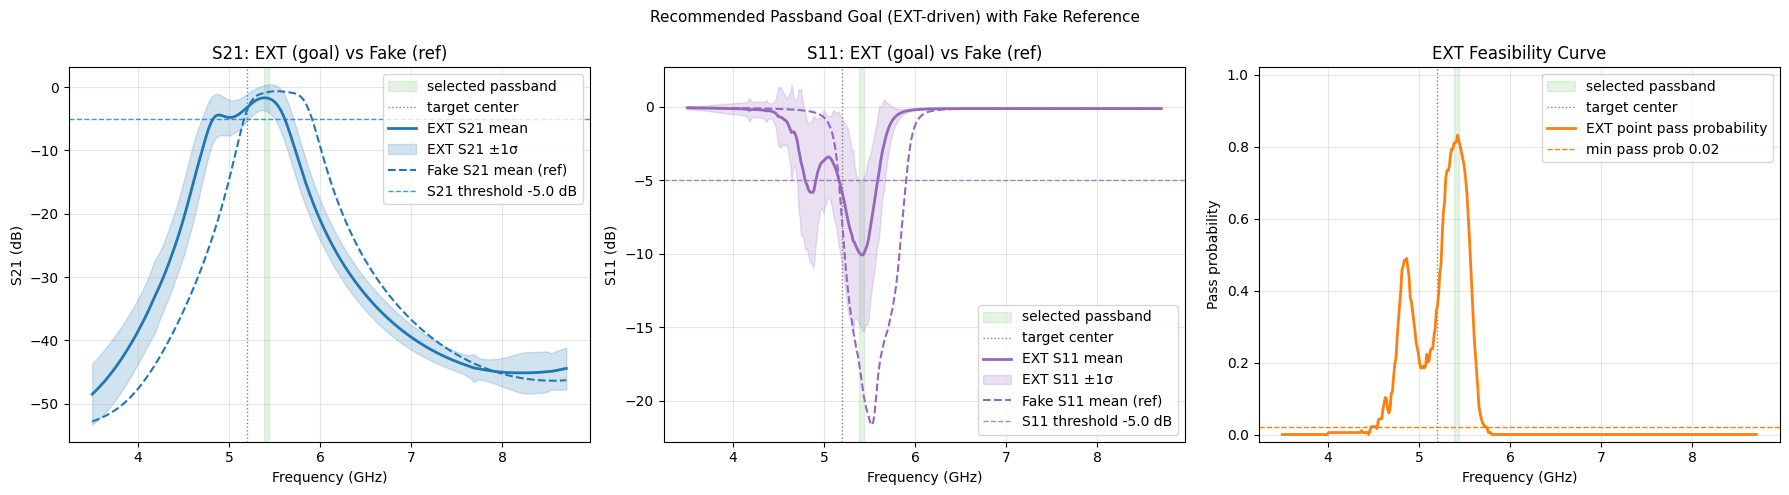

In [6]:
# Final plots: fake reference + ext diagnostics + selected goal
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

for ax in axes:
    ax.axvspan(fL, fH, color='tab:green', alpha=0.12, label='selected passband')
    ax.axvline(TARGET_CENTER_GHZ, color='gray', linestyle=':', lw=1, label='target center')
    ax.grid(True, alpha=0.3)

axes[0].plot(freq_ghz, ext_s21_mean, color='tab:blue', lw=2, label='EXT S21 mean')
axes[0].fill_between(freq_ghz, ext_s21_mean - ext_s21_std, ext_s21_mean + ext_s21_std, color='tab:blue', alpha=0.20, label='EXT S21 ±1σ')
axes[0].plot(freq_ghz, fake_s21_mean, color='tab:blue', lw=1.5, linestyle='--', label='Fake S21 mean (ref)')
axes[0].axhline(S21_PASS_DB, color='tab:blue', linestyle='--', lw=1, alpha=0.8, label=f'S21 threshold {S21_PASS_DB} dB')
axes[0].set_title('S21: EXT (goal) vs Fake (ref)')
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S21 (dB)')
axes[0].legend(loc='best')

axes[1].plot(freq_ghz, ext_s11_mean, color='tab:purple', lw=2, label='EXT S11 mean')
axes[1].fill_between(freq_ghz, ext_s11_mean - ext_s11_std, ext_s11_mean + ext_s11_std, color='tab:purple', alpha=0.20, label='EXT S11 ±1σ')
axes[1].plot(freq_ghz, fake_s11_mean, color='tab:purple', lw=1.5, linestyle='--', label='Fake S11 mean (ref)')
axes[1].axhline(S11_PASS_DB, color='tab:purple', linestyle='--', lw=1, alpha=0.8, label=f'S11 threshold {S11_PASS_DB} dB')
axes[1].set_title('S11: EXT (goal) vs Fake (ref)')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('S11 (dB)')
axes[1].legend(loc='best')

axes[2].plot(freq_ghz, point_pass_prob, color='tab:orange', lw=2, label='EXT point pass probability')
axes[2].axhline(MIN_PASS_PROB, color='tab:orange', linestyle='--', lw=1, label=f'min pass prob {MIN_PASS_PROB}')
axes[2].set_title('EXT Feasibility Curve')
axes[2].set_xlabel('Frequency (GHz)')
axes[2].set_ylabel('Pass probability')
axes[2].set_ylim(-0.02, 1.02)
axes[2].legend(loc='best')

fig.suptitle('Recommended Passband Goal (EXT-driven) with Fake Reference', fontsize=11)
plt.tight_layout()
plt.show()


## New Objective (Fixed Band)

Objective used for this experiment block:
- Band: **4.8–5.2 GHz**
- Constraint: **S21 >= -5 dB** and **S11 <= -7 dB** across the full band.


In [7]:
# New objective definition
OBJ_BAND_GHZ = (4.8, 5.4)
OBJ_S21_DB = -5.0
OBJ_S11_DB = -7.0

# Stop/restrict bands for S21 objective (as requested)
RESTRICT_LOWER_BAND_GHZ = (3.7, 4.5)
RESTRICT_UPPER_BAND_GHZ = (5.8, float(freq_ghz.max()))
RESTRICT_S21_DB = -15.0

obj_mask = (freq_ghz >= OBJ_BAND_GHZ[0]) & (freq_ghz <= OBJ_BAND_GHZ[1])
restrict_lower_mask = (freq_ghz >= RESTRICT_LOWER_BAND_GHZ[0]) & (freq_ghz <= RESTRICT_LOWER_BAND_GHZ[1])
restrict_upper_mask = (freq_ghz >= RESTRICT_UPPER_BAND_GHZ[0]) & (freq_ghz <= RESTRICT_UPPER_BAND_GHZ[1])

if int(obj_mask.sum()) == 0:
    raise RuntimeError('Objective band has zero frequency points on this grid')
if int(restrict_lower_mask.sum()) == 0 or int(restrict_upper_mask.sum()) == 0:
    raise RuntimeError('Restrict lower/upper band has zero frequency points')

# Full passband objective feasibility
ext_min_s21_in_band = ext_s21_db[:, obj_mask].min(axis=1)
ext_max_s11_in_band = ext_s11_db[:, obj_mask].max(axis=1)
ext_satisfy_mask = (ext_min_s21_in_band >= OBJ_S21_DB) & (ext_max_s11_in_band <= OBJ_S11_DB)
ext_satisfy_idx = np.where(ext_satisfy_mask)[0]

# Restrict-band S21 objective: max S21 in stop/restrict bands should be <= threshold
ext_max_s21_lower_restrict = ext_s21_db[:, restrict_lower_mask].max(axis=1)
ext_max_s21_upper_restrict = ext_s21_db[:, restrict_upper_mask].max(axis=1)
ext_s21_ok_lower_restrict = ext_max_s21_lower_restrict <= RESTRICT_S21_DB
ext_s21_ok_upper_restrict = ext_max_s21_upper_restrict <= RESTRICT_S21_DB

print('Passband objective: band=', OBJ_BAND_GHZ, 'S21>=', OBJ_S21_DB, 'S11<=', OBJ_S11_DB)
print('Restrict S21 objective: lower=', RESTRICT_LOWER_BAND_GHZ, 'upper=', RESTRICT_UPPER_BAND_GHZ, 'S21<=', RESTRICT_S21_DB)
print('EXT total cases:', int(ext_s21_db.shape[0]))
print('EXT satisfying cases (passband objective):', int(ext_satisfy_mask.sum()))
print('Restrict lower-band S21 satisfying cases:', int(ext_s21_ok_lower_restrict.sum()))
print('Restrict upper-band S21 satisfying cases:', int(ext_s21_ok_upper_restrict.sum()))
print('Restrict both-bands S21 satisfying cases:', int((ext_s21_ok_lower_restrict & ext_s21_ok_upper_restrict).sum()))
print('Restrict lower-band max-S21 stats [mean/min/max]:', float(ext_max_s21_lower_restrict.mean()), float(ext_max_s21_lower_restrict.min()), float(ext_max_s21_lower_restrict.max()))
print('Restrict upper-band max-S21 stats [mean/min/max]:', float(ext_max_s21_upper_restrict.mean()), float(ext_max_s21_upper_restrict.min()), float(ext_max_s21_upper_restrict.max()))


Passband objective: band= (4.8, 5.4) S21>= -5.0 S11<= -7.0
Restrict S21 objective: lower= (3.7, 4.5) upper= (5.8, 8.7) S21<= -15.0
EXT total cases: 184
EXT satisfying cases (passband objective): 2
Restrict lower-band S21 satisfying cases: 161
Restrict upper-band S21 satisfying cases: 48
Restrict both-bands S21 satisfying cases: 36
Restrict lower-band max-S21 stats [mean/min/max]: -21.219593429603766 -30.71117826592365 -1.2277590319343574
Restrict upper-band max-S21 stats [mean/min/max]: -13.254535137516783 -23.159427848962192 -2.7857929197468136


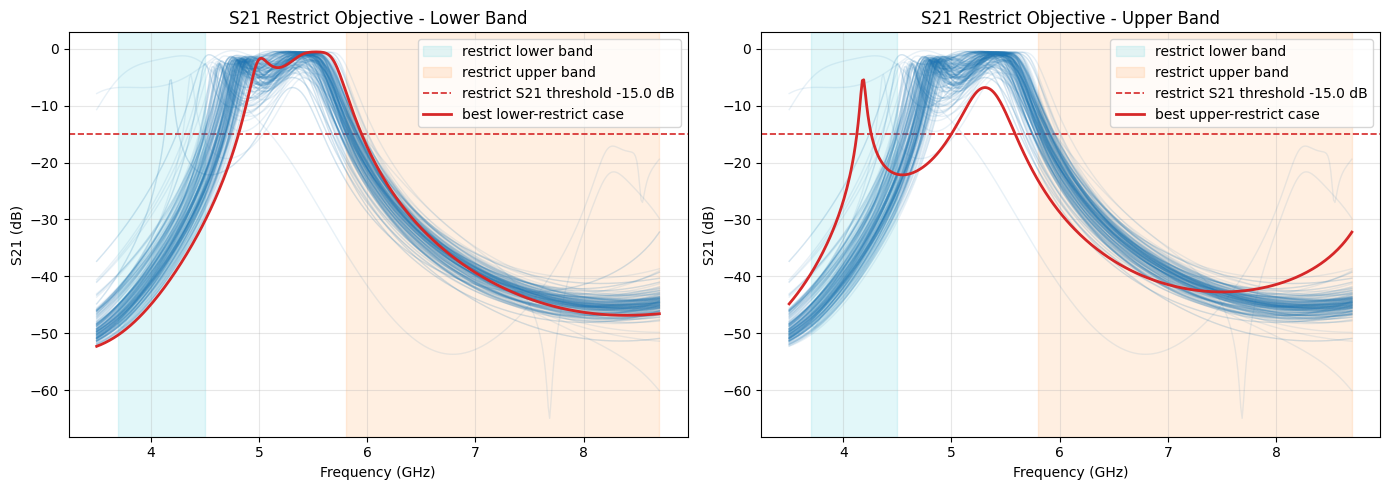

Best lower-restrict S21 case: Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d78_L1_8d14_L2_7d87_W_1d02_W1_0d85_W2_0d93_S1_0d14_S2_0d6.s2p
  lower-restrict max S21: -30.71117826592365 dB
Best upper-restrict S21 case: Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d81_L1_8d1_L2_7d98_W_0d92_W1_0d84_W2_0d97_S1_0d14_S2_0d58.s2p
  upper-restrict max S21: -23.159427848962192 dB


In [8]:
# Plot restrict-band S21 objectives and determine best cases (lower / upper)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax in axes:
    ax.axvspan(RESTRICT_LOWER_BAND_GHZ[0], RESTRICT_LOWER_BAND_GHZ[1], color='tab:cyan', alpha=0.12, label='restrict lower band')
    ax.axvspan(RESTRICT_UPPER_BAND_GHZ[0], RESTRICT_UPPER_BAND_GHZ[1], color='tab:orange', alpha=0.12, label='restrict upper band')
    ax.axhline(RESTRICT_S21_DB, color='tab:red', linestyle='--', lw=1.2, label=f'restrict S21 threshold {RESTRICT_S21_DB} dB')
    ax.grid(True, alpha=0.3)

for i in range(ext_s21_db.shape[0]):
    axes[0].plot(freq_ghz, ext_s21_db[i], color='tab:blue', alpha=0.10, linewidth=1.0)
    axes[1].plot(freq_ghz, ext_s21_db[i], color='tab:blue', alpha=0.10, linewidth=1.0)

# Best = minimum peak leakage in each restrict band
best_lower_idx = int(np.argmin(ext_max_s21_lower_restrict))
best_upper_idx = int(np.argmin(ext_max_s21_upper_restrict))

axes[0].plot(freq_ghz, ext_s21_db[best_lower_idx], color='tab:red', linewidth=2.0, label='best lower-restrict case')
axes[1].plot(freq_ghz, ext_s21_db[best_upper_idx], color='tab:red', linewidth=2.0, label='best upper-restrict case')

axes[0].set_title('S21 Restrict Objective - Lower Band')
axes[1].set_title('S21 Restrict Objective - Upper Band')
axes[0].set_xlabel('Frequency (GHz)')
axes[1].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S21 (dB)')
axes[1].set_ylabel('S21 (dB)')
axes[0].legend(loc='best')
axes[1].legend(loc='best')

plt.tight_layout()
plt.show()

print('Best lower-restrict S21 case:', ext_valid_records[best_lower_idx].get('filename', '<unknown>'))
print('  lower-restrict max S21:', float(ext_max_s21_lower_restrict[best_lower_idx]), 'dB')
print('Best upper-restrict S21 case:', ext_valid_records[best_upper_idx].get('filename', '<unknown>'))
print('  upper-restrict max S21:', float(ext_max_s21_upper_restrict[best_upper_idx]), 'dB')


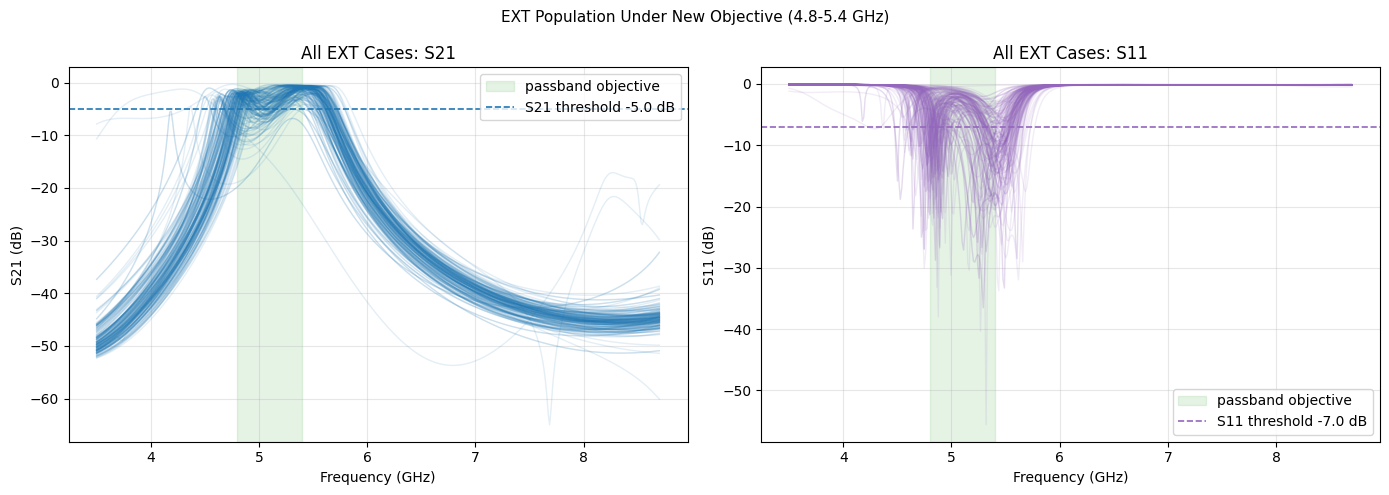

In [9]:
# Plot all EXT data under the new passband objective
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax in axes:
    ax.axvspan(OBJ_BAND_GHZ[0], OBJ_BAND_GHZ[1], color='tab:green', alpha=0.12, label='passband objective')
    ax.grid(True, alpha=0.3)

for i in range(ext_s21_db.shape[0]):
    axes[0].plot(freq_ghz, ext_s21_db[i], color='tab:blue', alpha=0.12, linewidth=1.0)
    axes[1].plot(freq_ghz, ext_s11_db[i], color='tab:purple', alpha=0.12, linewidth=1.0)

axes[0].axhline(OBJ_S21_DB, color='tab:blue', linestyle='--', lw=1.2, label=f'S21 threshold {OBJ_S21_DB} dB')
axes[1].axhline(OBJ_S11_DB, color='tab:purple', linestyle='--', lw=1.2, label=f'S11 threshold {OBJ_S11_DB} dB')

axes[0].set_title('All EXT Cases: S21')
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S21 (dB)')
axes[0].legend(loc='best')

axes[1].set_title('All EXT Cases: S11')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('S11 (dB)')
axes[1].legend(loc='best')

fig.suptitle('EXT Population Under New Objective (4.8-5.4 GHz)', fontsize=11)
plt.tight_layout()
plt.show()


Satisfying EXT case count: 2
Satisfying case filenames:
- Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d73_L1_8d19_L2_7d98_W_1d06_W1_0d8_W2_0d95_S1_0d15_S2_0d6.s2p
- Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d87_L1_8d08_L2_7d93_W_1d04_W1_0d78_W2_0d93_S1_0d15_S2_0d58.s2p


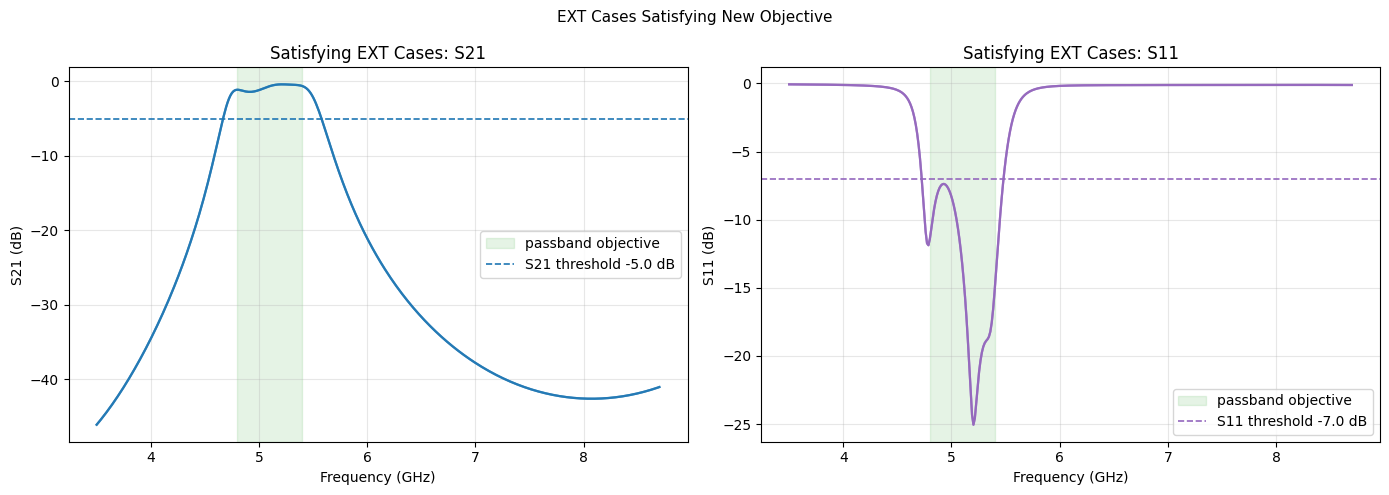

In [10]:
# Show only satisfying EXT cases
if len(ext_satisfy_idx) == 0:
    print('No EXT cases satisfy the new objective.')
else:
    print('Satisfying EXT case count:', int(len(ext_satisfy_idx)))
    if int(len(ext_satisfy_idx)) <= 10:
        print('Satisfying case filenames:')
        for i in ext_satisfy_idx:
            rec = ext_valid_records[i]
            print('-', rec.get('filename', '<unknown>'))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
    for ax in axes:
        ax.axvspan(OBJ_BAND_GHZ[0], OBJ_BAND_GHZ[1], color='tab:green', alpha=0.12, label='passband objective')
        ax.axvspan(RESTRICT_LOWER_BAND_GHZ[0], RESTRICT_LOWER_BAND_GHZ[1], color='tab:cyan', alpha=0.10, label='restrict lower')
        ax.axvspan(RESTRICT_UPPER_BAND_GHZ[0], RESTRICT_UPPER_BAND_GHZ[1], color='tab:orange', alpha=0.10, label='restrict upper')
        ax.grid(True, alpha=0.3)

    for i in ext_satisfy_idx:
        axes[0].plot(freq_ghz, ext_s21_db[i], color='tab:blue', alpha=0.85, linewidth=1.6)
        axes[1].plot(freq_ghz, ext_s11_db[i], color='tab:purple', alpha=0.85, linewidth=1.6)

    axes[0].axhline(OBJ_S21_DB, color='tab:blue', linestyle='--', lw=1.2, label=f'S21 threshold {OBJ_S21_DB} dB')
    axes[1].axhline(OBJ_S11_DB, color='tab:purple', linestyle='--', lw=1.2, label=f'S11 threshold {OBJ_S11_DB} dB')
    axes[0].set_title('Satisfying EXT Cases: S21')
    axes[1].set_title('Satisfying EXT Cases: S11')
    axes[0].set_xlabel('Frequency (GHz)')
    axes[1].set_xlabel('Frequency (GHz)')
    axes[0].set_ylabel('S21 (dB)')
    axes[1].set_ylabel('S11 (dB)')
    axes[0].legend(loc='best')
    axes[1].legend(loc='best')
    full_lo = float(freq_ghz.min())
    full_hi = float(freq_ghz.max())
    axes[0].set_xlim(full_lo, full_hi)
    axes[1].set_xlim(full_lo, full_hi)
    fig.suptitle('EXT Cases Satisfying New Objective', fontsize=11)
    plt.tight_layout()
    plt.show()
